In [12]:
# Librerías
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from matplotlib import style
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay
import statsmodels.api as sm
import statsmodels.formula.api as smf
from pathlib import Path

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

from sklearn.preprocessing import StandardScaler

from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

In [13]:
df = pd.read_csv('data/datos_preprocesados.csv')
df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Personas_Cargo,Fiador,Impago,Prima,Estudios_encoded,Estado_Civil_Divorciado,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,...,0,0,0,800.00,2,0,1,0,0,1
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,...,0,0,0,580.00,2,0,0,0,1,0
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,...,1,0,0,130.00,1,0,0,0,0,0
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,...,1,0,0,168.08,1,0,1,0,0,1
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,...,1,1,0,293.94,0,0,1,0,1,0


In [14]:
# describe de varibales numéricas contínuas
df[['Ratio_Interes', 'Duracion', 'Ratio_Deuda_Ingresos', 'Prima', 'Ingresos', 'Monto_Inicial', 'Scoring_Crediticio', 'Meses_Empleo', 'Num_Creditos']].describe()

,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Prima,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos
count,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000,178606.000000
mean,10.676211,37.255523,0.321933,386.809055,41509.970740,45190.765937,692.053285,212.770601,2.001025
std,3.809254,14.166838,0.181164,267.648386,16036.504202,46648.083692,87.828224,150.688070,1.001298
min,2.010000,12.000000,0.100000,10.000000,16000.000000,3000.000000,398.000000,0.000000,1.000000
25%,7.960000,24.000000,0.140000,138.880000,30484.250000,15126.000000,635.000000,70.000000,1.000000
50%,10.590000,36.000000,0.290000,340.095000,39090.500000,40000.000000,704.000000,208.000000,2.000000
75%,13.270000,48.000000,0.550000,621.670000,50096.750000,47626.500000,761.000000,336.000000,3.000000
max,24.440000,60.000000,0.550000,800.000000,120000.000000,400000.000000,845.000000,639.000000,4.000000


In [15]:
resumen = pd.DataFrame({
        "Frecuencia": df['Impago'].value_counts(),
        "Porcentaje": (
            df['Impago']
            .value_counts(normalize=True)
            .mul(100)
            .round(2)
        )
    })
resumen

,Frecuencia,Porcentaje
Impago,,
0,157832,88.37
1,20774,11.63


El 88.37% de los clientes han pagado y el 11.63% no. Un modelo de clasificación que sea útil debe de ser capaz de predecir correctamente un porcentaje de observaciones por encima del porcentaje de la clase mayoritaria. En este caso, el umbral de referencia que se tiene que superar es del 88.37%.

In [16]:
X = df.drop(columns=['Impago', 'ID'])
y = df['Impago']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.8,
    random_state=42,
    shuffle=True,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [17]:
# Función para evaluar las métricas
def evaluar_modelo(modelo, X_test, y_test):
    
    prediccion = modelo.predict(X_test)
    probabilidad = modelo.predict_proba(X_test)[:, 1]

    print("Cantidad de predicciones:")
    print(pd.Series(prediccion).value_counts())

    print("Matriz de confusión:")
    print(confusion_matrix(y_test, prediccion))

    print("\nInforme de clasificación:")
    print(classification_report(y_test, prediccion))

    print("ROC-AUC:", round(roc_auc_score(y_test, probabilidad), 3))
    print(
        "PR-AUC:",
        round(average_precision_score(y_test, probabilidad), 3)
    )

# 1. class_weight='balanced'

In [24]:
modelo_class_weight = LogisticRegression(
    class_weight='balanced',
    max_iter=2000,
    random_state=42
)

modelo_class_weight.fit(X_train_scaled, y_train)

evaluar_modelo(
    modelo_class_weight,
    X_test_scaled,
    y_test
)

Cantidad de predicciones:
0    21236
1    14486
Name: count, dtype: int64
Matriz de confusión:
[[19784 11783]
 [ 1452  2703]]

Informe de clasificación:
              precision    recall  f1-score   support

           0       0.93      0.63      0.75     31567
           1       0.19      0.65      0.29      4155

    accuracy                           0.63     35722
   macro avg       0.56      0.64      0.52     35722
weighted avg       0.84      0.63      0.70     35722

ROC-AUC: 0.689
PR-AUC: 0.224


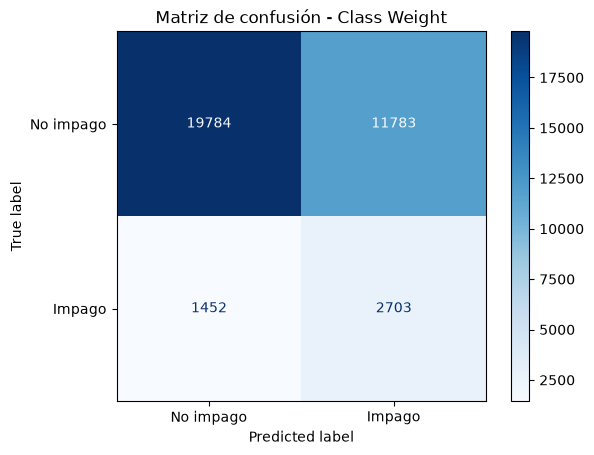

In [27]:
pred_class_weight = modelo_class_weight.predict(X_test_scaled)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_class_weight,
    display_labels=['No impago', 'Impago'],
    cmap='Blues',
    values_format='d'
)

plt.title("Matriz de confusión - Class Weight")
plt.show()

# 2. RandomOverSampler

Oversampler es una técnica de balanceado, duplica aleatoriamente observaciones de impago hasta igualar las dos clases

In [18]:
oversampler = RandomOverSampler(random_state=42)

X_train_over, y_train_over = oversampler.fit_resample(
    X_train_scaled,
    y_train
)

print("Distribución original:")
print(pd.Series(y_train).value_counts())

print("\nDistribución después del oversampling:")
print(pd.Series(y_train_over).value_counts())

Distribución original:
Impago
0    126265
1     16619
Name: count, dtype: int64

Distribución después del oversampling:
Impago
0    126265
1    126265
Name: count, dtype: int64


In [19]:
modelo_over = LogisticRegression(
    max_iter=2000,
    random_state=42
)

modelo_over.fit(X_train_over, y_train_over)

evaluar_modelo(
    modelo_over,
    X_test_scaled,
    y_test
)

Cantidad de predicciones:
0    21272
1    14450
Name: count, dtype: int64
Matriz de confusión:
[[19809 11758]
 [ 1463  2692]]

Informe de clasificación:
              precision    recall  f1-score   support

           0       0.93      0.63      0.75     31567
           1       0.19      0.65      0.29      4155

    accuracy                           0.63     35722
   macro avg       0.56      0.64      0.52     35722
weighted avg       0.84      0.63      0.70     35722

ROC-AUC: 0.689
PR-AUC: 0.224


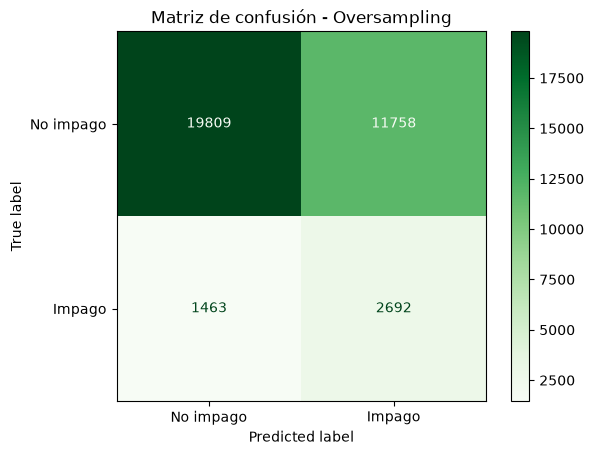

In [28]:
pred_over = modelo_over.predict(X_test_scaled)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_over,
    display_labels=['No impago', 'Impago'],
    cmap='Greens',
    values_format='d'
)

plt.title("Matriz de confusión - Oversampling")
plt.show()

# 3. RandomUnderSampler

RandomUnderSampler es una técnica de balanceado que reduce la clase mayoritaria hasta igualar las dos clases

In [20]:
undersampler = RandomUnderSampler(random_state=42)

X_train_under, y_train_under = undersampler.fit_resample(
    X_train_scaled,
    y_train
)

print("Distribución original:")
print(pd.Series(y_train).value_counts())

print("\nDistribución después del undersampling:")
print(pd.Series(y_train_under).value_counts())

Distribución original:
Impago
0    126265
1     16619
Name: count, dtype: int64

Distribución después del undersampling:
Impago
0    16619
1    16619
Name: count, dtype: int64


In [21]:
modelo_under = LogisticRegression(
    max_iter=2000,
    random_state=42
)

modelo_under.fit(X_train_under, y_train_under)

evaluar_modelo(
    modelo_under,
    X_test_scaled,
    y_test
)

Cantidad de predicciones:
0    21185
1    14537
Name: count, dtype: int64
Matriz de confusión:
[[19742 11825]
 [ 1443  2712]]

Informe de clasificación:
              precision    recall  f1-score   support

           0       0.93      0.63      0.75     31567
           1       0.19      0.65      0.29      4155

    accuracy                           0.63     35722
   macro avg       0.56      0.64      0.52     35722
weighted avg       0.85      0.63      0.70     35722

ROC-AUC: 0.689
PR-AUC: 0.224


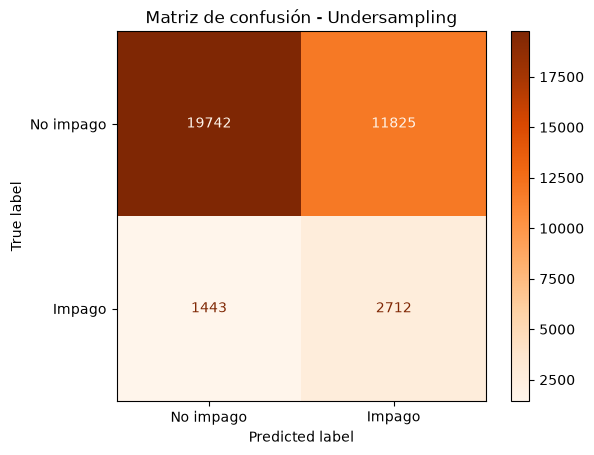

In [29]:
pred_under = modelo_under.predict(X_test_scaled)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_under,
    display_labels=['No impago', 'Impago'],
    cmap='Oranges',
    values_format='d'
)

plt.title("Matriz de confusión - Undersampling")
plt.show()